# Salon Experiment & Causal Analysis\n\nThis notebook follows the v2.0 design document. It is a scaffold: update file paths and column mappings after the real data are supplied. Do not invent or report effects from placeholder data.

## 0. Imports and reproducibility

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_quality import sample_ratio_mismatch, standardised_mean_difference
from src.experiment import retention_difference_ci, welch_revenue_test, client_bootstrap_mean_difference
from src.cuped import apply_cuped

SEED = 2026
np.random.seed(SEED)
DATA_DIR = PROJECT_ROOT / "data"


In [2]:
# ==========================================
# STEP 7: LOAD SYNTHETIC DATA
# ==========================================

from pathlib import Path
import pandas as pd

# Find data folder
if Path("data").exists():
    DATA_DIR = Path("data")
else:
    DATA_DIR = Path("../data")

# Load datasets
customers = pd.read_csv(DATA_DIR / "customers.csv")
outlets = pd.read_csv(DATA_DIR / "outlets.csv")
appointments = pd.read_csv(DATA_DIR / "appointments.csv")
assignment = pd.read_csv(DATA_DIR / "experiment_assignment.csv")
outcomes = pd.read_csv(DATA_DIR / "customer_outcomes.csv")

print("All datasets loaded successfully!")

print("\nDataset shapes:")
print("Customers:", customers.shape)
print("Outlets:", outlets.shape)
print("Appointments:", appointments.shape)
print("Assignment:", assignment.shape)
print("Outcomes:", outcomes.shape)

# Preview customer data
display(customers.head())

All datasets loaded successfully!

Dataset shapes:
Customers: (10000, 6)
Outlets: (22, 2)
Appointments: (43422, 6)
Assignment: (10000, 4)
Outcomes: (10000, 2)


,customer_id,outlet_id,baseline_visits,frequency_band,experiment_group,retained_90d
0,CUST_00001,OUT_07,2,Low,Control,0
1,CUST_00002,OUT_20,3,Low,Treatment,1
2,CUST_00003,OUT_15,4,High,Control,1
3,CUST_00004,OUT_11,2,Low,Treatment,1
4,CUST_00005,OUT_08,1,Low,Control,1


In [3]:
# ==========================================
# STEP 8: DATA QUALITY AUDIT
# ==========================================

# 1. Missing values
print("1. MISSING VALUES")
print("\nCustomers:")
print(customers.isnull().sum())

print("\nAppointments:")
print(appointments.isnull().sum())


# 2. Duplicate records
print("\n2. DUPLICATE RECORDS")

print("Duplicate customers:",
      customers["customer_id"].duplicated().sum())

print("Duplicate outlets:",
      outlets["outlet_id"].duplicated().sum())

print("Duplicate appointment rows:",
      appointments.duplicated().sum())


# 3. Unique records
print("\n3. UNIQUE RECORDS")

print("Unique customers:",
      customers["customer_id"].nunique())

print("Unique outlets:",
      outlets["outlet_id"].nunique())


# 4. Experiment group distribution
print("\n4. EXPERIMENT GROUP DISTRIBUTION")

print(customers["experiment_group"].value_counts())


# 5. Appointment status
print("\n5. APPOINTMENT STATUS")

print(appointments["status"].value_counts())


# 6. Revenue summary
print("\n6. REVENUE SUMMARY")

print(appointments["revenue"].describe())


# 7. Date range
appointments["appointment_date"] = pd.to_datetime(
    appointments["appointment_date"],
    format="mixed"
)
print("\n7. APPOINTMENT DATE RANGE")

print("Start date:", appointments["appointment_date"].min())
print("End date:", appointments["appointment_date"].max())


print("\nDATA QUALITY AUDIT COMPLETED!")

1. MISSING VALUES

Customers:
customer_id         0
outlet_id           0
baseline_visits     0
frequency_band      0
experiment_group    0
retained_90d        0
dtype: int64

Appointments:
customer_id         0
appointment_date    0
outlet_id           0
service             0
revenue             0
status              0
dtype: int64

2. DUPLICATE RECORDS
Duplicate customers: 0
Duplicate outlets: 0
Duplicate appointment rows: 0

3. UNIQUE RECORDS
Unique customers: 10000
Unique outlets: 22

4. EXPERIMENT GROUP DISTRIBUTION
experiment_group
Control      5012
Treatment    4988
Name: count, dtype: int64

5. APPOINTMENT STATUS
status
Completed    35460
Cancelled     4792
No-show       3170
Name: count, dtype: int64

6. REVENUE SUMMARY
count    43422.000000
mean       816.411036
std        413.081656
min        300.000000
25%        500.000000
50%        600.000000
75%       1200.000000
max       1500.000000
Name: revenue, dtype: float64

7. APPOINTMENT DATE RANGE
Start date: 2025-01-01 00:03

RETENTION SUMMARY


,count,sum,mean,retention_rate
experiment_group,,,,
Control,5012,1538,0.306864,30.686353
Treatment,4988,1770,0.354852,35.485164



Treatment Retention: 35.49 %
Control Retention: 30.69 %
Retention Difference: 4.8 percentage points


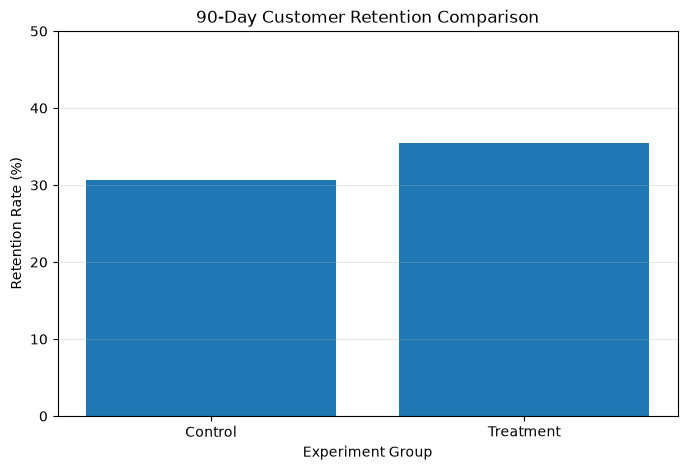

In [4]:
# ==========================================
# STEP 9: RETENTION ANALYSIS
# ==========================================

import matplotlib.pyplot as plt

# Calculate retention by experiment group
retention_summary = (
    customers.groupby("experiment_group")["retained_90d"]
    .agg(["count", "sum", "mean"])
)

# Convert retention rate into percentage
retention_summary["retention_rate"] = (
    retention_summary["mean"] * 100
)

print("RETENTION SUMMARY")
display(retention_summary)

# Calculate difference in retention
treatment_rate = retention_summary.loc[
    "Treatment", "retention_rate"
]

control_rate = retention_summary.loc[
    "Control", "retention_rate"
]

difference = treatment_rate - control_rate

print("\nTreatment Retention:", round(treatment_rate, 2), "%")
print("Control Retention:", round(control_rate, 2), "%")
print("Retention Difference:", round(difference, 2), "percentage points")


# Create comparison chart
plt.figure(figsize=(8, 5))

plt.bar(
    ["Control", "Treatment"],
    [
        control_rate,
        treatment_rate
    ]
)

plt.title("90-Day Customer Retention Comparison")
plt.ylabel("Retention Rate (%)")
plt.xlabel("Experiment Group")

plt.ylim(0, 50)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [5]:
# ==========================================
# STEP 10: STATISTICAL SIGNIFICANCE TEST
# ==========================================

import numpy as np
from scipy.stats import norm

# Group sample sizes
n_treatment = len(
    customers[customers["experiment_group"] == "Treatment"]
)

n_control = len(
    customers[customers["experiment_group"] == "Control"]
)

# Number of retained customers
success_treatment = customers.loc[
    customers["experiment_group"] == "Treatment",
    "retained_90d"
].sum()

success_control = customers.loc[
    customers["experiment_group"] == "Control",
    "retained_90d"
].sum()

# Retention proportions
p_treatment = success_treatment / n_treatment
p_control = success_control / n_control

# Difference in proportions
effect = p_treatment - p_control

# Pooled proportion for hypothesis test
pooled = (
    success_treatment + success_control
) / (n_treatment + n_control)

# Standard error for Z-test
se_test = np.sqrt(
    pooled * (1 - pooled) *
    (1/n_treatment + 1/n_control)
)

# Z statistic
z_stat = effect / se_test

# Two-sided p-value
p_value = 2 * norm.sf(abs(z_stat))

# 95% Confidence interval
se_ci = np.sqrt(
    p_treatment * (1 - p_treatment) / n_treatment
    +
    p_control * (1 - p_control) / n_control
)

ci_lower = effect - 1.96 * se_ci
ci_upper = effect + 1.96 * se_ci

# Display results
print("STATISTICAL TEST RESULTS")
print("------------------------")

print("Treatment sample size:", n_treatment)
print("Control sample size:", n_control)

print("\nRetention difference:",
      round(effect * 100, 2), "percentage points")

print("Z-statistic:", round(z_stat, 4))
print("P-value:", round(p_value, 6))

print("\n95% Confidence Interval:")
print(
    round(ci_lower * 100, 2),
    "to",
    round(ci_upper * 100, 2),
    "percentage points"
)

# Statistical decision
if p_value < 0.05:
    print("\nResult: Statistically significant")
else:
    print("\nResult: Not statistically significant")

STATISTICAL TEST RESULTS
------------------------
Treatment sample size: 4988
Control sample size: 5012

Retention difference: 4.8 percentage points
Z-statistic: 5.0997
P-value: 0.0

95% Confidence Interval:
2.96 to 6.64 percentage points

Result: Statistically significant


OUTLET-WISE RETENTION SUMMARY


experiment_group,Control,Treatment
outlet_id,,
OUT_01,29.86,36.20
OUT_02,34.05,32.90
OUT_03,27.07,32.89
OUT_04,28.89,30.80
OUT_05,26.99,41.96
OUT_06,33.18,39.82
OUT_07,29.09,39.27
OUT_08,25.33,35.27
OUT_09,30.41,28.70


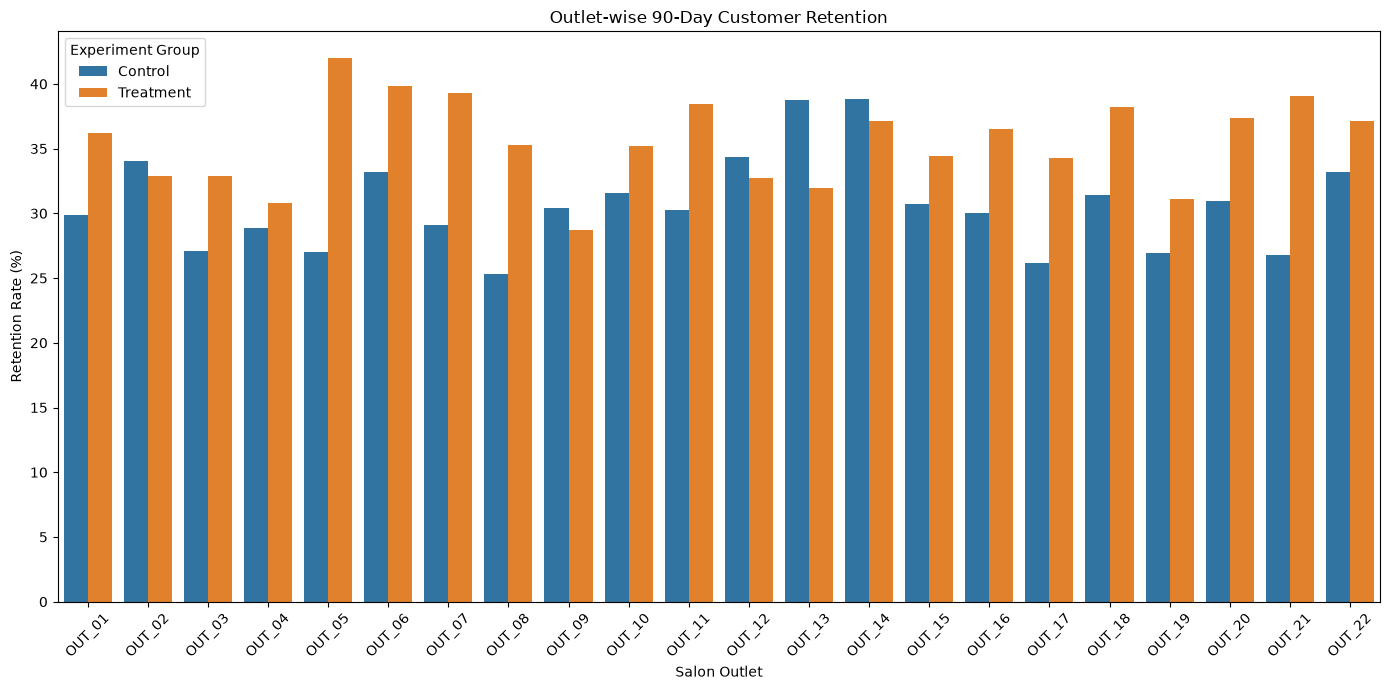

In [6]:
# ==========================================
# STEP 11: OUTLET-WISE RETENTION ANALYSIS
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate retention rate for each outlet and experiment group
outlet_analysis = (
    customers.groupby(
        ["outlet_id", "experiment_group"]
    )["retained_90d"]
    .mean()
    .reset_index()
)

# Convert to percentage
outlet_analysis["retention_rate"] = (
    outlet_analysis["retained_90d"] * 100
)

# Display results
print("OUTLET-WISE RETENTION SUMMARY")

display(
    outlet_analysis.pivot(
        index="outlet_id",
        columns="experiment_group",
        values="retention_rate"
    ).round(2)
)

# Create comparison chart
plt.figure(figsize=(14, 7))

sns.barplot(
    data=outlet_analysis,
    x="outlet_id",
    y="retention_rate",
    hue="experiment_group"
)

plt.title("Outlet-wise 90-Day Customer Retention")
plt.xlabel("Salon Outlet")
plt.ylabel("Retention Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Experiment Group")
plt.tight_layout()
plt.show()

REVENUE SUMMARY


,count,mean,median,sum
experiment_group,,,,
Control,5012,2866.76,2700.0,14368200.0
Treatment,4988,2914.21,2700.0,14536100.0



Average Treatment Revenue: 2914.21
Average Control Revenue: 2866.76
Revenue Difference per Customer: 47.45


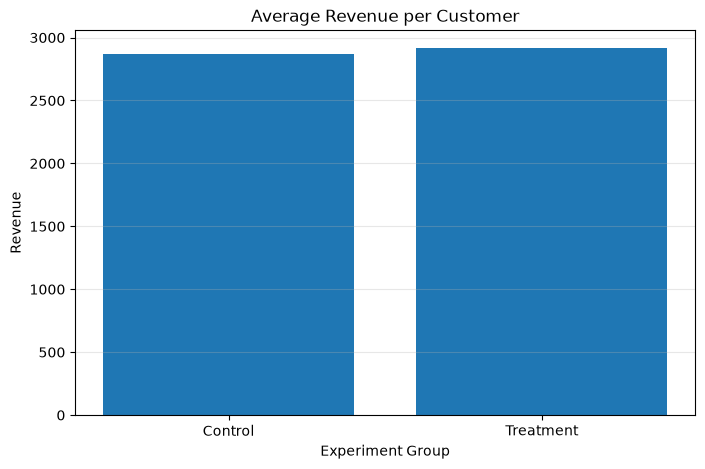

In [7]:
# ==========================================
# STEP 12: REVENUE ANALYSIS
# ==========================================

# Keep only completed appointments
completed_appointments = appointments[
    appointments["status"] == "Completed"
].copy()

# Calculate revenue per customer
customer_revenue = (
    completed_appointments.groupby("customer_id")["revenue"]
    .sum()
    .reset_index()
)

customer_revenue.rename(
    columns={"revenue": "total_revenue"},
    inplace=True
)

# Attach experiment group
revenue_analysis = customers[
    ["customer_id", "experiment_group"]
].merge(
    customer_revenue,
    on="customer_id",
    how="left"
)

# Customers with no completed appointments have zero revenue
revenue_analysis["total_revenue"] = (
    revenue_analysis["total_revenue"].fillna(0)
)

# Revenue summary by experiment group
revenue_summary = (
    revenue_analysis.groupby("experiment_group")["total_revenue"]
    .agg(["count", "mean", "median", "sum"])
)

print("REVENUE SUMMARY")
display(revenue_summary.round(2))

# Calculate revenue difference
treatment_revenue = revenue_summary.loc["Treatment", "mean"]
control_revenue = revenue_summary.loc["Control", "mean"]

revenue_difference = treatment_revenue - control_revenue

print("\nAverage Treatment Revenue:", round(treatment_revenue, 2))
print("Average Control Revenue:", round(control_revenue, 2))
print("Revenue Difference per Customer:", round(revenue_difference, 2))

# Revenue comparison chart
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    ["Control", "Treatment"],
    [control_revenue, treatment_revenue]
)

plt.title("Average Revenue per Customer")
plt.ylabel("Revenue")
plt.xlabel("Experiment Group")
plt.grid(axis="y", alpha=0.3)

plt.show()

APPOINTMENT STATUS DISTRIBUTION (%)


status,Cancelled,Completed,No-show
experiment_group,,,
Control,11.14,81.54,7.32
Treatment,10.93,81.79,7.28



NO-SHOW RATE (%)


experiment_group
Control      7.32
Treatment    7.28
Name: status, dtype: float64


CANCELLATION RATE (%)


experiment_group
Control      11.14
Treatment    10.93
Name: status, dtype: float64

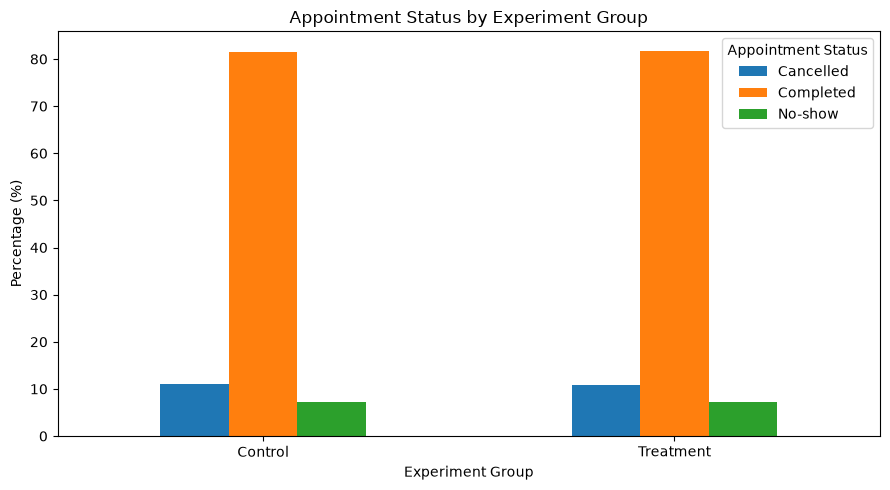

In [8]:
# ==========================================
# STEP 13: NO-SHOW AND CANCELLATION ANALYSIS
# ==========================================

# Attach experiment group to every appointment
appointment_analysis = appointments.merge(
    customers[["customer_id", "experiment_group"]],
    on="customer_id",
    how="left"
)

# Calculate appointment status by experiment group
status_summary = pd.crosstab(
    appointment_analysis["experiment_group"],
    appointment_analysis["status"],
    normalize="index"
) * 100

print("APPOINTMENT STATUS DISTRIBUTION (%)")
display(status_summary.round(2))

# Calculate no-show rate
no_show_summary = (
    appointment_analysis.groupby("experiment_group")["status"]
    .apply(lambda x: (x == "No-show").mean() * 100)
)

print("\nNO-SHOW RATE (%)")
display(no_show_summary.round(2))

# Calculate cancellation rate
cancellation_summary = (
    appointment_analysis.groupby("experiment_group")["status"]
    .apply(lambda x: (x == "Cancelled").mean() * 100)
)

print("\nCANCELLATION RATE (%)")
display(cancellation_summary.round(2))

# Visualize appointment status
status_summary.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Appointment Status by Experiment Group")
plt.xlabel("Experiment Group")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Appointment Status")
plt.tight_layout()
plt.show()

RETENTION BY CUSTOMER SEGMENT


,frequency_band,experiment_group,count,mean,retention_rate
0,High,Control,1759,0.30,30.47
1,High,Treatment,1744,0.38,37.79
2,Low,Control,3253,0.31,30.80
3,Low,Treatment,3244,0.34,34.25



TREATMENT EFFECT BY SEGMENT (DESCRIPTIVE)


experiment_group,Control,Treatment,difference_pp
frequency_band,,,
High,30.47,37.79,7.31
Low,30.80,34.25,3.45



REVENUE BY CUSTOMER SEGMENT


,frequency_band,experiment_group,count,mean,median
0,High,Control,1759,4136.90,4000.0
1,High,Treatment,1744,4210.15,4100.0
2,Low,Control,3253,2179.96,2100.0
3,Low,Treatment,3244,2217.51,2100.0


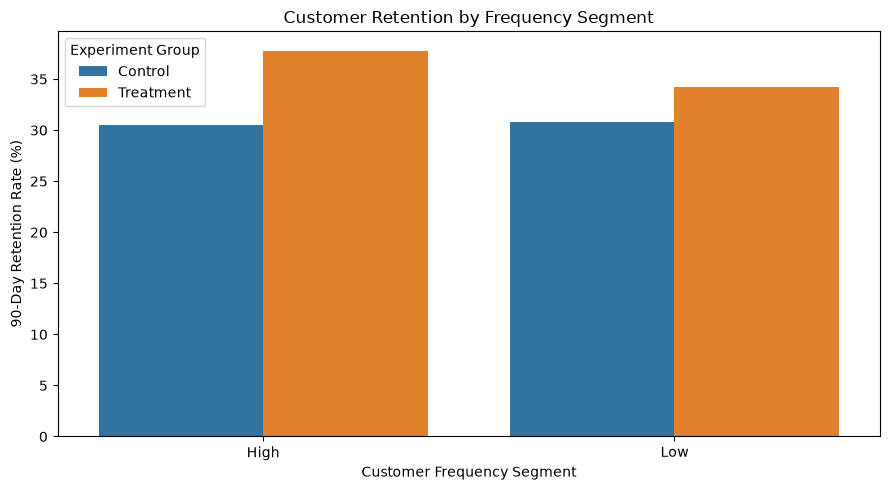


CUSTOMER SEGMENTATION COMPLETED!


In [9]:
# ==========================================
# STEP 14: CUSTOMER SEGMENTATION ANALYSIS
# ==========================================

# 1. Retention by customer segment and experiment group

segment_retention = (
    customers.groupby(
        ["frequency_band", "experiment_group"]
    )["retained_90d"]
    .agg(["count", "mean"])
    .reset_index()
)

segment_retention["retention_rate"] = (
    segment_retention["mean"] * 100
)

print("RETENTION BY CUSTOMER SEGMENT")
display(segment_retention.round(2))


# 2. Calculate retention difference by segment

segment_pivot = segment_retention.pivot(
    index="frequency_band",
    columns="experiment_group",
    values="retention_rate"
)

segment_pivot["difference_pp"] = (
    segment_pivot["Treatment"] -
    segment_pivot["Control"]
)

print("\nTREATMENT EFFECT BY SEGMENT (DESCRIPTIVE)")
display(segment_pivot.round(2))


# 3. Revenue by customer segment

segment_revenue = revenue_analysis.merge(
    customers[["customer_id", "frequency_band"]],
    on="customer_id",
    how="left"
)

revenue_by_segment = (
    segment_revenue.groupby(
        ["frequency_band", "experiment_group"]
    )["total_revenue"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

print("\nREVENUE BY CUSTOMER SEGMENT")
display(revenue_by_segment.round(2))


# 4. Visualize retention

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=segment_retention,
    x="frequency_band",
    y="retention_rate",
    hue="experiment_group"
)

plt.title("Customer Retention by Frequency Segment")
plt.xlabel("Customer Frequency Segment")
plt.ylabel("90-Day Retention Rate (%)")
plt.legend(title="Experiment Group")
plt.tight_layout()
plt.show()


print("\nCUSTOMER SEGMENTATION COMPLETED!")

In [10]:
# ==========================================
# STEP 15: DIFFERENCE-IN-DIFFERENCES
# ==========================================

# 1. Identify completed pre-experiment visits
pre_visits = appointments[
    (appointments["appointment_date"] < "2025-07-01") &
    (appointments["status"] == "Completed")
]

pre_outcome = (
    pre_visits.groupby("customer_id")
    .size()
    .gt(0)
    .astype(int)
    .rename("pre_visit")
)

# 2. Identify completed repeat visits after experiment start
post_visits = appointments[
    (appointments["appointment_date"] > "2025-07-01") &
    (appointments["status"] == "Completed")
]

post_outcome = (
    post_visits.groupby("customer_id")
    .size()
    .gt(0)
    .astype(int)
    .rename("post_visit")
)

# 3. Combine pre and post outcomes
did_data = customers[
    ["customer_id", "experiment_group"]
].copy()

did_data = did_data.merge(
    pre_outcome,
    on="customer_id",
    how="left"
)

did_data = did_data.merge(
    post_outcome,
    on="customer_id",
    how="left"
)

did_data[["pre_visit", "post_visit"]] = (
    did_data[["pre_visit", "post_visit"]].fillna(0)
)

# 4. Calculate group-level averages
did_summary = (
    did_data.groupby("experiment_group")[
        ["pre_visit", "post_visit"]
    ].mean()
)

print("PRE AND POST VISIT RATES")
display((did_summary * 100).round(2))

# 5. Calculate Difference-in-Differences
treatment_change = (
    did_summary.loc["Treatment", "post_visit"]
    - did_summary.loc["Treatment", "pre_visit"]
)

control_change = (
    did_summary.loc["Control", "post_visit"]
    - did_summary.loc["Control", "pre_visit"]
)

did_effect = treatment_change - control_change

print("\nTREATMENT GROUP CHANGE:",
      round(treatment_change * 100, 2), "percentage points")

print("CONTROL GROUP CHANGE:",
      round(control_change * 100, 2), "percentage points")

print("\nDIFFERENCE-IN-DIFFERENCES EFFECT:",
      round(did_effect * 100, 2), "percentage points")

print("\nDID ANALYSIS COMPLETED!")

PRE AND POST VISIT RATES


,pre_visit,post_visit
experiment_group,,
Control,91.20,30.69
Treatment,90.84,35.49



TREATMENT GROUP CHANGE: -55.35 percentage points
CONTROL GROUP CHANGE: -60.51 percentage points

DIFFERENCE-IN-DIFFERENCES EFFECT: 5.16 percentage points

DID ANALYSIS COMPLETED!


In [11]:

# STEP 16: CUPED Analysis

import numpy as np
import pandas as pd

# Outcome (Y) and pre-experiment covariate (X)
Y = customers["retained_90d"].astype(float)
X = customers["baseline_visits"].astype(float)

# Calculate CUPED theta
theta = np.cov(Y, X, ddof=1)[0, 1] / np.var(X, ddof=1)

# Adjust outcome using CUPED
customers["retained_cuped"] = Y - theta * (X - X.mean())

# Calculate adjusted group means
cuped_results = customers.groupby("experiment_group").agg(
    original_retention=("retained_90d", "mean"),
    cuped_retention=("retained_cuped", "mean"),
    customers=("customer_id", "count")
)

print("CUPED THETA:", round(theta, 4))
print("\nCUPED RESULTS:")
print(cuped_results)

# Calculate treatment effects
original_effect = (
    cuped_results.loc["Treatment", "original_retention"]
    - cuped_results.loc["Control", "original_retention"]
) * 100

adjusted_effect = (
    cuped_results.loc["Treatment", "cuped_retention"]
    - cuped_results.loc["Control", "cuped_retention"]
) * 100

print("\nORIGINAL TREATMENT EFFECT:", round(original_effect, 2), "percentage points")
print("CUPED-ADJUSTED TREATMENT EFFECT:", round(adjusted_effect, 2), "percentage points")


CUPED THETA: 0.0043

CUPED RESULTS:
                  original_retention  cuped_retention  customers
experiment_group                                                
Control                     0.306864         0.306876       5012
Treatment                   0.354852         0.354839       4988

ORIGINAL TREATMENT EFFECT: 4.8 percentage points
CUPED-ADJUSTED TREATMENT EFFECT: 4.8 percentage points


In [12]:

# STEP 17: Robustness and Randomization Checks

from scipy.stats import chisquare
import pandas as pd
import numpy as np

# 1. Sample Ratio Mismatch (SRM) Check
group_counts = customers["experiment_group"].value_counts()

observed = np.array([
    group_counts.get("Control", 0),
    group_counts.get("Treatment", 0)
])

expected = np.array([
    len(customers) / 2,
    len(customers) / 2
])

chi_stat, srm_pvalue = chisquare(observed, f_exp=expected)

print("1. SAMPLE RATIO MISMATCH CHECK")
print("Control customers:", observed[0])
print("Treatment customers:", observed[1])
print("SRM p-value:", round(srm_pvalue, 4))

if srm_pvalue < 0.01:
    print("WARNING: Possible sample ratio mismatch")
else:
    print("PASS: No significant sample ratio mismatch detected")


# 2. Baseline Balance Check
balance = customers.groupby("experiment_group").agg(
    avg_baseline_visits=("baseline_visits", "mean"),
    avg_baseline_visits_sd=("baseline_visits", "std"),
    customer_count=("customer_id", "count")
)

print("\n2. BASELINE BALANCE CHECK")
print(balance)


# 3. Standardized Mean Difference (SMD)
control_mean = balance.loc["Control", "avg_baseline_visits"]
treatment_mean = balance.loc["Treatment", "avg_baseline_visits"]

control_sd = balance.loc["Control", "avg_baseline_visits_sd"]
treatment_sd = balance.loc["Treatment", "avg_baseline_visits_sd"]

pooled_sd = np.sqrt((control_sd**2 + treatment_sd**2) / 2)

smd = (treatment_mean - control_mean) / pooled_sd

print("\n3. STANDARDIZED MEAN DIFFERENCE")
print("Baseline visits SMD:", round(smd, 4))

if abs(smd) < 0.1:
    print("PASS: Baseline characteristic is well balanced")
else:
    print("CHECK: Baseline imbalance may be present")


print("\nROBUSTNESS CHECKS COMPLETED!")


1. SAMPLE RATIO MISMATCH CHECK
Control customers: 5012
Treatment customers: 4988
SRM p-value: 0.8103
PASS: No significant sample ratio mismatch detected

2. BASELINE BALANCE CHECK
                  avg_baseline_visits  avg_baseline_visits_sd  customer_count
experiment_group                                                             
Control                      3.008579                1.719309            5012
Treatment                    3.014234                1.743531            4988

3. STANDARDIZED MEAN DIFFERENCE
Baseline visits SMD: 0.0033
PASS: Baseline characteristic is well balanced

ROBUSTNESS CHECKS COMPLETED!


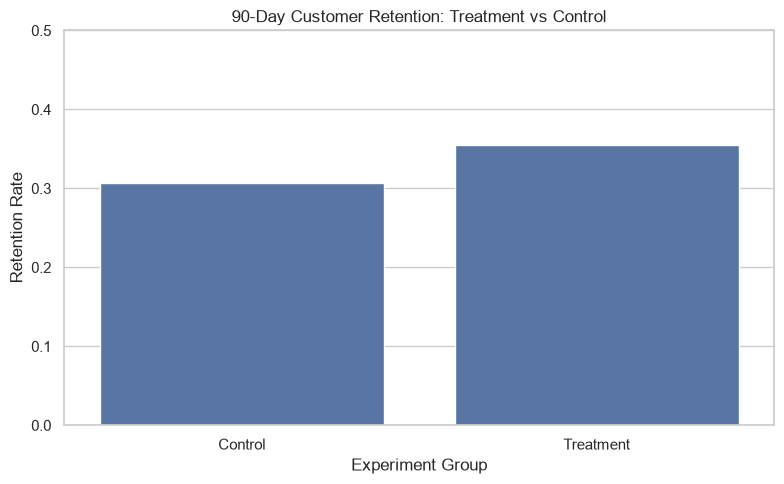

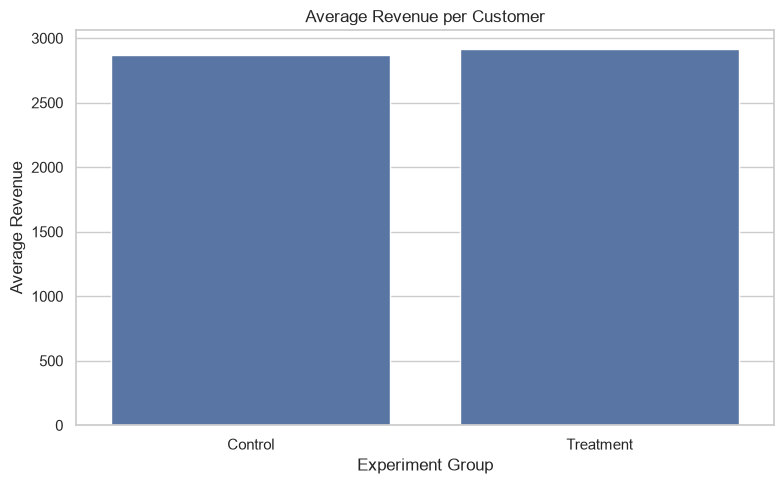

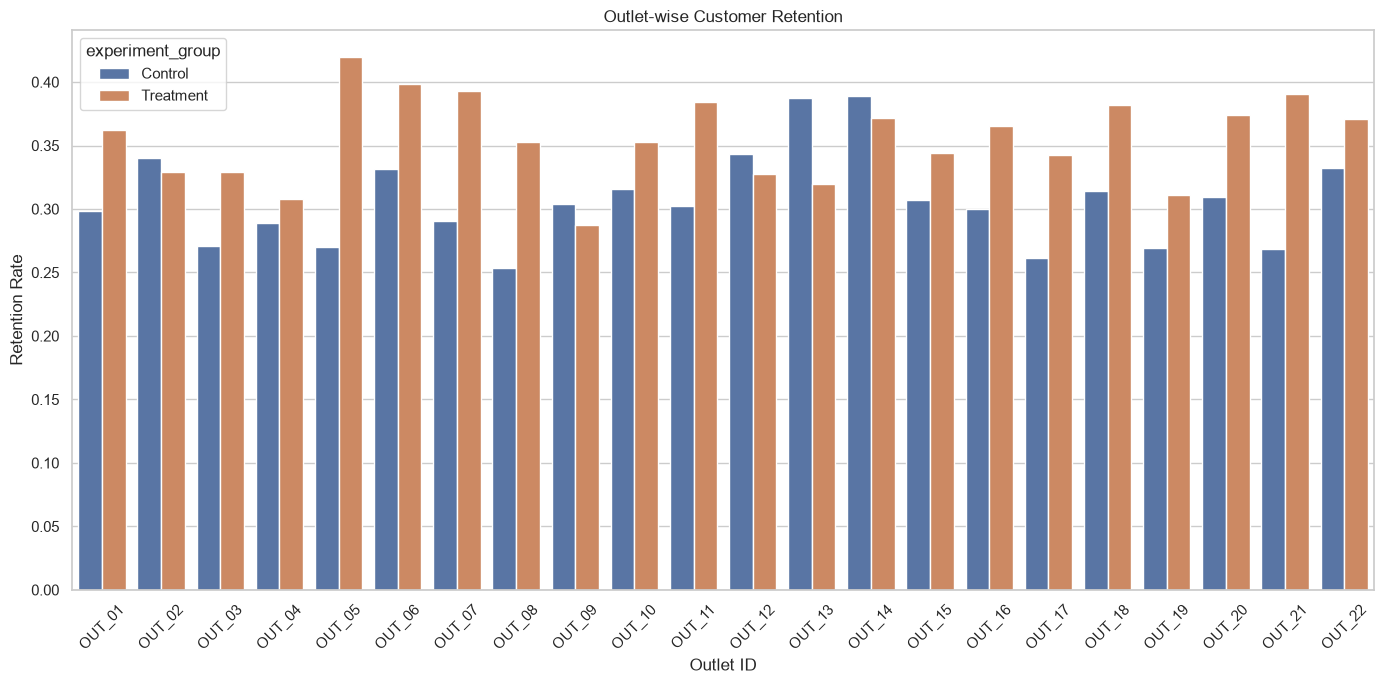

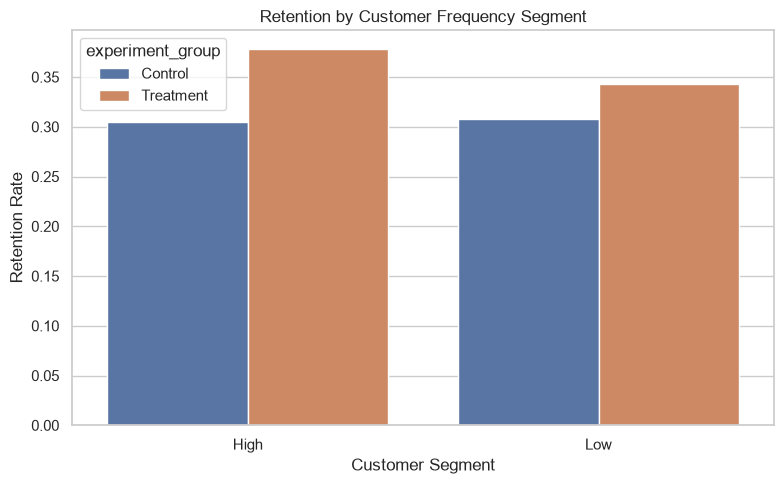

ALL FOUR VISUALIZATIONS GENERATED SUCCESSFULLY!


In [13]:

# STEP 18: Professional Data Visualizations

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid", palette="deep")

# 1. Treatment vs Control Retention
plt.figure(figsize=(8, 5))

sns.barplot(
    data=customers,
    x="experiment_group",
    y="retained_90d",
    errorbar=None
)

plt.title("90-Day Customer Retention: Treatment vs Control")
plt.xlabel("Experiment Group")
plt.ylabel("Retention Rate")
plt.ylim(0, 0.5)
plt.tight_layout()
plt.show()


# 2. Average Revenue Comparison
# Use completed appointments only
completed = appointments[
    appointments["status"] == "Completed"
].copy()

# Identify the revenue column
if "revenue" in completed.columns:
    amount_col = "revenue"
elif "price" in completed.columns:
    amount_col = "price"
else:
    raise ValueError(
        "Revenue/price column not found. Check appointments.columns"
    )

revenue_per_customer = (
    completed.groupby("customer_id")[amount_col]
    .sum()
    .reset_index(name="total_revenue")
)

revenue_data = customers[
    ["customer_id", "experiment_group"]
].merge(
    revenue_per_customer,
    on="customer_id",
    how="left"
)

revenue_data["total_revenue"] = (
    revenue_data["total_revenue"].fillna(0)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=revenue_data,
    x="experiment_group",
    y="total_revenue",
    errorbar=None
)

plt.title("Average Revenue per Customer")
plt.xlabel("Experiment Group")
plt.ylabel("Average Revenue")
plt.tight_layout()
plt.show()


# 3. Outlet-wise Retention
outlet_retention = (
    customers.groupby(
        ["outlet_id", "experiment_group"]
    )["retained_90d"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=outlet_retention,
    x="outlet_id",
    y="retained_90d",
    hue="experiment_group"
)

plt.title("Outlet-wise Customer Retention")
plt.xlabel("Outlet ID")
plt.ylabel("Retention Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 4. Customer Segment-wise Retention
segment_retention = (
    customers.groupby(
        ["frequency_band", "experiment_group"]
    )["retained_90d"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=segment_retention,
    x="frequency_band",
    y="retained_90d",
    hue="experiment_group"
)

plt.title("Retention by Customer Frequency Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Retention Rate")
plt.tight_layout()
plt.show()

print("ALL FOUR VISUALIZATIONS GENERATED SUCCESSFULLY!")


In [14]:

# STEP 19: Business Insights and Recommendations

# 1. Overall Retention Results
retention_summary = customers.groupby("experiment_group")[
    "retained_90d"
].agg(["count", "sum", "mean"])

treatment_retention = retention_summary.loc["Treatment", "mean"]
control_retention = retention_summary.loc["Control", "mean"]

retention_lift = (
    treatment_retention - control_retention
) * 100

print("1. CUSTOMER RETENTION INSIGHTS")
print("Treatment Retention:", round(treatment_retention * 100, 2), "%")
print("Control Retention:", round(control_retention * 100, 2), "%")
print("Retention Improvement:", round(retention_lift, 2), "percentage points")


# 2. Revenue Insights
revenue_insights = revenue_data.groupby("experiment_group")[
    "total_revenue"
].mean()

revenue_difference = (
    revenue_insights["Treatment"] -
    revenue_insights["Control"]
)

print("\n2. REVENUE INSIGHTS")
print("Treatment Average Revenue:", round(revenue_insights["Treatment"], 2))
print("Control Average Revenue:", round(revenue_insights["Control"], 2))
print("Revenue Difference:", round(revenue_difference, 2))


# 3. Customer Segment Insights
print("\n3. CUSTOMER SEGMENT INSIGHTS")

segment_comparison = segment_retention.pivot(
    index="frequency_band",
    columns="experiment_group",
    values="retained_90d"
)

segment_comparison["treatment_lift_pp"] = (
    segment_comparison["Treatment"] -
    segment_comparison["Control"]
) * 100

print(segment_comparison.round(2))


# 4. Business Recommendations
print("\n4. BUSINESS RECOMMENDATIONS")

if retention_lift > 0:
    print("- Personalised reminders show a positive retention signal.")
else:
    print("- Personalised reminders did not show a positive retention signal.")

if revenue_difference > 0:
    print("- Treatment group generated higher average revenue.")
else:
    print("- Treatment group did not generate higher average revenue.")

print("- Monitor performance separately across all 22 outlets.")
print("- Evaluate customer segments before scaling the campaign.")
print("- Run a longer real-world experiment before full implementation.")

print("\nBUSINESS INSIGHTS COMPLETED!")


1. CUSTOMER RETENTION INSIGHTS
Treatment Retention: 35.49 %
Control Retention: 30.69 %
Retention Improvement: 4.8 percentage points

2. REVENUE INSIGHTS
Treatment Average Revenue: 2914.21
Control Average Revenue: 2866.76
Revenue Difference: 47.45

3. CUSTOMER SEGMENT INSIGHTS
experiment_group  Control  Treatment  treatment_lift_pp
frequency_band                                         
High                 0.30       0.38               7.31
Low                  0.31       0.34               3.45

4. BUSINESS RECOMMENDATIONS
- Personalised reminders show a positive retention signal.
- Treatment group generated higher average revenue.
- Monitor performance separately across all 22 outlets.
- Evaluate customer segments before scaling the campaign.
- Run a longer real-world experiment before full implementation.

BUSINESS INSIGHTS COMPLETED!


## 1. Load data (configure after receiving the dataset)

## 2. Schema, row-grain and key validation\n\nCheck row counts, date ranges, duplicate primary keys, orphan foreign keys and missingness. Keep an exclusion log for every cleaning rule.

In [16]:

from pathlib import Path
import pandas as pd

# Locate project root
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
elif not (PROJECT_DIR / "data").exists():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"

# Load actual project datasets
appointments = pd.read_csv(DATA_DIR / "appointments.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
assignment = pd.read_csv(DATA_DIR / "experiment_assignment.csv")
customer_outcomes = pd.read_csv(DATA_DIR / "customer_outcomes.csv")
outlets = pd.read_csv(DATA_DIR / "outlets.csv")

print("ALL DATASETS LOADED SUCCESSFULLY!")
print("Appointments:", appointments.shape)
print("Customers:", customers.shape)
print("Experiment Assignment:", assignment.shape)
print("Customer Outcomes:", customer_outcomes.shape)
print("Outlets:", outlets.shape)


ALL DATASETS LOADED SUCCESSFULLY!
Appointments: (43422, 6)
Customers: (10000, 6)
Experiment Assignment: (10000, 4)
Customer Outcomes: (10000, 2)
Outlets: (22, 2)


In [17]:
# Example checks once dataframes are loaded:
# assert appointments["appointment_id"].notna().all()
# print("Rows:", len(appointments))
# print("Duplicate appointment IDs:", appointments["appointment_id"].duplicated().sum())
# display(appointments.isna().mean().sort_values(ascending=False).head(20))


## 3. Recover no-shows and map service taxonomy\n\nApply the exact rule in the design document. Validate recovered no-shows against a manually reviewed 300-record sample. Keep disputed records flagged for sensitivity analysis. Map service names with RapidFuzz score bands: >=90 auto-map, 70–89 manual review, <70 unmapped.

In [18]:
# TODO: implement against the source-specific status and cancellation fields.
# Do not classify every cancellation as a no-show.


## 4. Build visit-level and client-level analytical tables\n\nA visit groups service lines for the same client and outlet within a 30-minute window. Keep anonymous walk-ins for outlet-level revenue/capacity only; exclude them from client-level retention.

In [ ]:
# TODO: build visits and client outcomes.
# Reconcile net revenue to POS within +/-0.5%.
# Exclude clients whose 90-day outcome window is immature; count them in the QA log.


## 5. Assignment validation and SRM (run before exclusions)

In [ ]:
# assignment must contain one row per randomised client and treatment in {0, 1}.
# assert assignment["client_id"].is_unique
# assert set(assignment["treatment"].dropna().unique()).issubset({0, 1})
# srm = sample_ratio_mismatch(assignment)
# print(srm)
# assert srm["p_value"] > 0.001, "SRM red flag: investigate assignment pipeline before outcome analysis."


## 6. Pre-treatment balance

In [ ]:
# For each pre-treatment covariate, calculate SMD between arms.
# Use |SMD| <= 0.10 as the practical threshold and report the maximum.
# Include prior 90-day visits / retention history as a key covariate.


## 7. ITT effect estimates and confidence intervals

In [ ]:
# client_level must contain one row per randomised eligible client with a mature outcome.
# retention_result = retention_difference_ci(client_level)
# revenue_result = welch_revenue_test(client_level)
# revenue_bootstrap = client_bootstrap_mean_difference(
#     client_level, outcome="revenue_per_visit", n_boot=10_000, seed=SEED
# )
# print(retention_result, revenue_result, revenue_bootstrap)


## 8. Guardrails

In [ ]:
# Evaluate contribution margin (non-inferiority margin -5%),
# complaints/refunds (+2 per 1,000 visits), capacity / booking lead-time,
# and opt-out rate (hard ceiling 1.5%). Guardrails are evaluated regardless
# of whether the primary outcome passes.


## 9. Historical Difference-in-Differences and event study

In [ ]:
# Build outlet-month panel with >=12 months pre-period and post-period.
# Fit outlet and month fixed effects with treated_outlet x post.
# Check parallel trends with event-study leads, slope comparison, placebo dates
# and Honest DiD sensitivity. If rollout is staggered, use a heterogeneity-robust
# group-time estimator rather than naive TWFE.


## 10. Segment interactions and multiple testing

In [ ]:
# Pre-specify outlet tier, service category, new/returning status,
# baseline frequency, spend tier and stylist level.
# Use treatment x segment interactions; report CIs and apply BH FDR at q=0.10.


## 11. CUPED / regression adjustment

In [ ]:
# Example after client_level is ready:
# adjusted, cuped_info = apply_cuped(client_level, "retained_90d", "pre_90d_visits")
# print(cuped_info)
# Compare unadjusted and adjusted effect estimates, CI widths, required sample
# and calendar-time savings. Covariates must be measured before randomisation.


## 12. Decision memo inputs\n\nApply the pre-registered rule: **GO** only if the lower 95% CI bound on retention exceeds +2.0 pp, delivery is >90%, SRM/balance pass and all guardrails hold. **NO-GO** if the upper bound is below +2.0 pp, the estimate is negative, or a hard guardrail breaks. Otherwise **EXTEND**. Do not write a decision until the actual data and assumption tests are complete.